In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
from magnetron.trajectories import ElectronTrajectory
from magnetron.parameters import (
    GeometryParameters,
    MeshSettings,
    MagneticParameters,
    ElectrostaticParameters
)
from magnetron.geometry import MagnetronGeometry
from magnetron.mesh import MagnetronMesh
from magnetron.magnetostatic import MagnetostaticSimulation
from magnetron.electrostatic import ElectrostaticSimulation
from magnetron.utils import FieldInterpolator2D

In [3]:
results_dir = Path("../results/experiment")

geometry_parameters = GeometryParameters(
    target_diameter=50.8,
    target_thickness=3.0,
    magnet_height=10.0,
    inner_magnet_diameter=15.0,
    outer_magnet_diameter=8.0,
    outer_magnet_ring_radius=18.0,
    magnet_to_target_distance=5.0,
)

geometry = MagnetronGeometry(geometry_parameters)

mesh_path = MagnetronMesh(
    geometry,
    MeshSettings(min_size=0.025, max_size=0.5),
).generate(results_dir / "mesh.msh")

Info    : Meshing 1D...                                                                                                  
Info    : [  0%] Meshing curve 15 (Line)
Info    : [ 10%] Meshing curve 19 (Line)
Info    : [ 10%] Meshing curve 23 (Line)
Info    : [ 10%] Meshing curve 24 (Line)
Info    : [ 20%] Meshing curve 25 (Line)
Info    : [ 20%] Meshing curve 26 (Line)
Info    : [ 20%] Meshing curve 27 (Line)
Info    : [ 20%] Meshing curve 28 (Line)
Info    : [ 30%] Meshing curve 29 (Line)
Info    : [ 30%] Meshing curve 30 (Line)
Info    : [ 30%] Meshing curve 31 (Line)
Info    : [ 30%] Meshing curve 32 (Line)
Info    : [ 40%] Meshing curve 33 (Line)
Info    : [ 40%] Meshing curve 34 (Line)
Info    : [ 40%] Meshing curve 35 (Line)
Info    : [ 40%] Meshing curve 36 (Line)
Info    : [ 50%] Meshing curve 37 (Line)
Info    : [ 50%] Meshing curve 38 (Line)
Info    : [ 50%] Meshing curve 39 (Line)
Info    : [ 60%] Meshing curve 40 (Line)
Info    : [ 60%] Meshing curve 41 (Line)
Info    : [ 60%] 

In [4]:
magnetic_parameters = MagneticParameters(
    remanence=2.0,
    mu_r_air=1.0,
    mu_r_magnet=1.05,
    mu_r_backing=1.0,
)

magnetic_result = MagnetostaticSimulation(
    mesh_path,
    magnetic_parameters,
).solve(results_dir)

Info    : Reading '../results/experiment/mesh.msh'...
Info    : 80 entities
Info    : 23017 nodes
Info    : 45472 elements
Info    : Done reading '../results/experiment/mesh.msh'
Magnetostatic problem solved.
Fields: ../results/experiment/fields.xdmf
Metadata: ../results/experiment/simulation.json
|B| min/max [T]: 0.00022019190494958405 1.8233605816474965


In [5]:
electrostatic_parameters = ElectrostaticParameters(
    target_voltage=-400.0, ground_voltage=0.0, eps_r_air=1.0
)

electrostatic_result = ElectrostaticSimulation(
    mesh_path, electrostatic_parameters
).solve(results_dir)

Info    : Reading '../results/experiment/mesh.msh'...
Info    : 80 entities
Info    : 23017 nodes
Info    : 45472 elements
Info    : Done reading '../results/experiment/mesh.msh'


In [9]:
E_field = FieldInterpolator2D(
    electrostatic_result.domain,
    {
        "Ex": electrostatic_result.ex,
        "Ey": electrostatic_result.ey,
    },
)

B_field = FieldInterpolator2D(
    magnetic_result.domain,
    {
        "Bx": magnetic_result.bx,
        "By": magnetic_result.by,
    },
)

def electric_field(x, y):
    values = E_field.evaluate(x, y)
    return [values["Ex"], values["Ey"], 0.0]


def magnetic_field(x, y):
    values = B_field.evaluate(x, y)
    return [values["Bx"], values["By"], 0.0]

In [10]:
sim = ElectronTrajectory(electric_field, magnetic_field)

x0 = 0.0
y0 = 0.01

print("E =", electric_field(x0, y0), "V/m")
print("B =", magnetic_field(x0, y0), "T")

E = [4.463415214346281e-05, 5.237233826719755, 0.0] V/m
B = [-0.0002982868079254847, 0.4015920405712985, 0.0] T


In [11]:
result = sim.solve(
    initial_position=(x0, y0),
    initial_velocity=(0.0, 1e5, 0.0),
    duration=1e-9,
    max_step=1e-12,
)

In [ ]:
x0 = 0.0
y0 = 0.005

print("Potential [V]:", E_field.evaluate(x0, y0))
print("E [V/m]:", electric_field(x0, y0))
print("B [T]:", magnetic_field(x0, y0))

Potential [V]: {'Ex': 4.5194762634657405e-05, 'Ey': 5.316539449398648}
E [V/m]: [4.5194762634657405e-05, 5.316539449398648, 0.0]
B [T]: [-0.00029846597438708006, 0.4018550540302311, 0.0]


In [17]:
V_field = FieldInterpolator2D(
    electrostatic_result.domain,
    {"V": electrostatic_result.potential},
)

print("V [V]:", V_field.evaluate(x0, y0))

V [V]: {'V': -399.99999999999994}


In [18]:
result = sim.solve(
    initial_position=(x0, y0),
    initial_velocity=(0.0, 0.0, 0.0),
    duration=1e-8,
    max_step=1e-12,
)

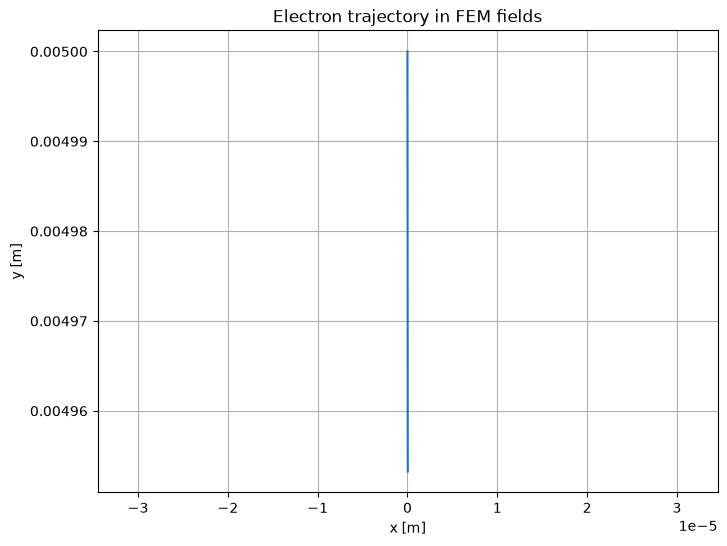

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(
    result.position[:, 0],
    result.position[:, 1],
)
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Electron trajectory in FEM fields")
plt.axis("equal")
plt.grid()
plt.show()

In [21]:

import numpy as np

electron_mass = 9.1093837139e-31  # kg
elementary_charge = 1.602176634e-19  # C

velocity = result.velocity
speed = np.linalg.norm(velocity, axis=1)
energy_eV = 0.5 * electron_mass * speed**2 / elementary_charge

print("Initial velocity [m/s]:", velocity[0])
print("Final velocity [m/s]:", velocity[-1])

print("Initial position [m]:", result.position[0])
print("Final position [m]:", result.position[-1])

print(f"Initial kinetic energy [eV]: {energy_eV[0]:.6f}")
print(f"Final kinetic energy [eV]: {energy_eV[-1]:.6f}")
print(f"Maximum kinetic energy [eV]: {energy_eV.max():.6f}")


Initial velocity [m/s]: [0. 0. 0.]
Final velocity [m/s]: [ 6.9446713e+00 -9.3512655e+03  1.9856799e-02]
Initial position [m]: [0.    0.005]
Final position [m]: [3.47256695e-08 4.95324476e-03]
Initial kinetic energy [eV]: 0.000000
Final kinetic energy [eV]: 0.000249
Maximum kinetic energy [eV]: 0.000249


In [22]:
print("V:", V_field.evaluate(x0, y0))
print("E:", electric_field(x0, y0))
print("B:", magnetic_field(x0, y0))

V: {'V': -399.99999999999994}
E: [4.5194762634657405e-05, 5.316539449398648, 0.0]
B: [-0.00029846597438708006, 0.4018550540302311, 0.0]


In [ ]:
for y_mm in [3.1, 3.5, 4.0, 5.0, 6.0, 8.0, 10.0, 40, 100]:
    x, y = 0.0, y_mm * 1e-3

    try:
        V = V_field.evaluate(x, y)["V"]
        E = electric_field(x, y)
        print(
            f"y={y_mm:4.1f} mm | "
            f"V={V:8.2f} V | "
            f"Ex={E[0]:9.3f} V/m | "
            f"Ey={E[1]:9.3f} V/m"
        )
    except ValueError as exc:
        print(f"y={y_mm:4.1f} mm | poza siatką: {exc}")

y= 3.1 mm | V= -400.00 V | Ex=    0.000 V/m | Ey=    5.347 V/m
y= 3.5 mm | V= -400.00 V | Ex=    0.000 V/m | Ey=    5.340 V/m
y= 4.0 mm | V= -400.00 V | Ex=    0.000 V/m | Ey=    5.332 V/m
y= 5.0 mm | V= -400.00 V | Ex=    0.000 V/m | Ey=    5.317 V/m
y= 6.0 mm | V= -400.00 V | Ex=    0.000 V/m | Ey=    5.301 V/m
y= 8.0 mm | V= -400.00 V | Ex=    0.000 V/m | Ey=    5.269 V/m
y=10.0 mm | V= -400.00 V | Ex=    0.000 V/m | Ey=    5.237 V/m
y=40.0 mm | V= -400.00 V | Ex=    0.000 V/m | Ey=    4.761 V/m
y=100.0 mm | V= -400.00 V | Ex=    0.000 V/m | Ey=    3.810 V/m
